In [228]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import matplotlib.patches as patches
import matplotlib.cm as cm
import matplotlib.colors as mcolors

In [229]:
STEP_SIZE = 20

In [ ]:
def discrete_mutation(individual, num_types, mutation_rate=0.1):
    mutated = individual.copy()
    for i in range(len(mutated)):
        if np.random.rand() < mutation_rate:
            mutated[i] = np.random.randint(0, num_types)
    return mutated

def gaussian_mutation(individual, sigma=0.1):
    noise = np.random.normal(0, sigma, size=len(individual))
    return individual + noise

def single_point_crossover(parent1, parent2):
    k = np.random.randint(1, len(parent1))
    
    child1 = np.concatenate([parent1[:k], parent2[k:]])
    child2 = np.concatenate([parent2[:k], parent1[k:]])
    return child1, child2

In [258]:
def rank_selection(combined_population, combined_scores, pop_size):
    # łączymy rodziców i dzieci, sortujemy i ucinamy do rozmiaru populacji - selekcja rankingowa
    sorted_indices = np.argsort(combined_scores)
    best_indices = sorted_indices[:pop_size]

    population = combined_population[best_indices]
    scores = combined_scores[best_indices]    

    return population, scores

def tournament_selection(population, scores, pop_size, k=3):
    new_population = []
    new_scores = []
    
    total_pool_size = len(population)
    
    for _ in range(pop_size):
        participants_idx = np.random.choice(total_pool_size, size=k, replace=False)
        winner_idx = participants_idx[np.argmin(scores[participants_idx])]
        
        new_population.append(population[winner_idx].copy())
        new_scores.append(scores[winner_idx])
        
    return np.array(new_population), np.array(new_scores)


def roulette_wheel_selection(population, scores, pop_size):
    # elitaryzm - najlepszy osobnik przechodzi
    best_idx = np.argmin(scores)
    elite_individual = population[best_idx].copy()
    elite_score = scores[best_idx]

    worst_score = np.max(scores)
    fitness = worst_score - scores + 1e-6 
    
    probabilities = fitness / np.sum(fitness)
    
    total_pool_size = len(population)
    selected_indices = np.random.choice(total_pool_size, size=pop_size-1, p=probabilities)
    
    new_population = population[selected_indices].copy()
    new_scores = scores[selected_indices].copy()

    final_population = np.vstack((elite_individual, new_population))
    final_scores = np.append(elite_score, new_scores)
    
    return final_population, final_scores

In [259]:
class EvolutionaryAlgorithm:
    def __init__(self, objective_func, mutation_op, crossover_op, selection_op, num_types, pop_size=100, chromosome_length=100, crossover_prob=0.8, mutation_prob=0.1):
        self.objective_func = objective_func
        self.mutation_op = mutation_op
        self.crossover_op = crossover_op
        self.selection_op = selection_op
        self.pop_size = pop_size
        self.chromosome_length = chromosome_length
        self.num_types = num_types

        self.crossover_prob = crossover_prob
        self.mutation_prob = mutation_prob

        # Inicjalizacja populacji - losowanie kolejności prostokątów
        self.population = np.random.randint(0, num_types, size=(pop_size, chromosome_length))
        
    def train(self, generations=1000):
        scores = np.array([self.objective_func(ind) for ind in tqdm(self.population, desc="Inicjalizacja")])
        history_best = []
        history_all = []

        # warunek stopu to dana liczba iteracji
        for gen in range(generations):
            children = []

            # KRZYŻOWANIE
            # losowe parowanie
            indices = np.arange(self.pop_size)
            np.random.shuffle(indices)

            for i in range(0, self.pop_size - 1, 2):
                parent1 = self.population[indices[i]]
                parent2 = self.population[indices[i+1]]
                
                if np.random.rand() < self.crossover_prob:
                    child1, child2 = self.crossover_op(parent1, parent2)
                else:
                    child1, child2 = parent1.copy(), parent2.copy()
                    
                children.extend([child1, child2])

            # MUTACJA
            mutated_children = []
            for child in children:
                if np.random.rand() < self.mutation_prob:
                    mutated_children.append(self.mutation_op(child))
                else:
                    mutated_children.append(child)
            
            mutated_children = np.array(mutated_children)

            # EWALUACJA
            children_scores = np.array([self.objective_func(c) for c in mutated_children])

            # SELEKCJA
            combined_population = np.vstack((self.population, mutated_children))
            combined_scores = np.concatenate((scores, children_scores))
            self.population, scores = self.selection_op(combined_population, combined_scores, self.pop_size)

            best_current_score = np.min(scores)
            avg_current_score = np.mean(scores)
            
            history_best.append(best_current_score)
            history_all.append(scores.copy())
            
            if gen % 1 == 0:
                print(f"Generacja {gen}: Najlepszy = {best_current_score:.4f}, Średni = {avg_current_score:.4f}")
        
        best_idx = np.argmin(scores)
        best_individual = self.population[best_idx]
        best_score = scores[best_idx]
        
        return best_individual, best_score, history_best, history_all

In [260]:
def create_circle_mask(radius):
    size = 2 * radius
    board = np.ones((size, size), dtype=np.int8)
    
    cx, cy = radius, radius
    y, x = np.ogrid[:size, :size]
    inside_circle = (x - cx)**2 + (y - cy)**2 <= radius**2
    board[inside_circle] = 0
    
    return board

In [261]:
def cutting_stock_fitness(individual, radius, rectangles_pool, step=STEP_SIZE):
    board = create_circle_mask(radius)
    size = 2 * radius
    total_value = 0
    
    for rect_id in individual:
        w = int(rectangles_pool.iloc[rect_id]['width'])
        h = int(rectangles_pool.iloc[rect_id]['height'])
        val = rectangles_pool.iloc[rect_id]['value']
        
        placed = False
        
        for y in range(0, size - h + 1, step):
            for x in range(0, size - w + 1, step):
                
                if (board[y, x] == 0 and 
                    board[y + h - 1, x] == 0 and 
                    board[y, x + w - 1] == 0 and 
                    board[y + h - 1, x + w - 1] == 0):
                    
                    window = board[y:y+h, x:x+w]
                    
                    if not np.any(window):
                        board[y:y+h, x:x+w] = 1
                        total_value += val
                        placed = True
                        break
            
            if placed:
                break
                
    return -total_value

In [262]:
def plot(history_all, hist_best):
    plt.figure(figsize=(10, 6))
    generations = len(history_all)
    
    for gen in range(generations):
        scores = history_all[gen]
        x_values = [gen] * len(scores)
        plt.scatter(x_values, scores, color='steelblue', alpha=0.1, s=15, edgecolors='none')

    plt.plot(hist_best, color='black', linewidth=1.5, label='Najlepszy wynik')

    plt.title("Wizualizacja całej populacji", fontsize=14)
    plt.xlabel("Generacja", fontsize=12)
    plt.ylabel("Wartość funkcji celu", fontsize=12)
    plt.legend(fontsize=12)
    #plt.yscale('log')
    
    plt.grid(True, alpha=0.3)
    plt.show()

In [263]:
def draw_packing(individual, radius, rectangles_pool, step=STEP_SIZE):
    board = create_circle_mask(radius)
    size = 2 * radius
    placed_rectangles = []
    total_value = 0
    
    for rect_id in individual:
        w = int(rectangles_pool.iloc[rect_id]['width'])
        h = int(rectangles_pool.iloc[rect_id]['height'])
        val = rectangles_pool.iloc[rect_id]['value']
        
        placed = False
        
        for y in range(0, size - h + 1, step):
            for x in range(0, size - w + 1, step):
                window = board[y:y+h, x:x+w]
                
                if not np.any(window):
                    board[y:y+h, x:x+w] = 1
                    placed_rectangles.append((x, y, w, h, val))
                    total_value += val
                    placed = True
                    break
            if placed:
                break
                
    fig, ax = plt.subplots(figsize=(10, 10))
    
    circle = patches.Circle((radius, radius), radius, edgecolor='black', facecolor='whitesmoke', linewidth=2, linestyle='--')
    ax.add_patch(circle)
    
    if placed_rectangles:
        values = [rect[4] for rect in placed_rectangles]
        min_val, max_val = min(values), max(values)
        
        norm = mcolors.Normalize(vmin=min_val, vmax=max_val) if min_val != max_val else mcolors.Normalize(vmin=0, vmax=max_val)
        
        cmap = plt.get_cmap('coolwarm')
        
        for x, y, w, h, val in placed_rectangles:
            color = cmap(norm(val))
            
            rect = patches.Rectangle(
                (x, y), w, h, 
                linewidth=1.5, 
                edgecolor='black', 
                facecolor=color, 
                alpha=0.85
            )
            ax.add_patch(rect)
            
            center_x = x + (w / 2)
            center_y = y + (h / 2)
            
            ax.text(
                center_x, center_y, 
                f"{val}", 
                color='black', 
                fontsize=max(6, min(10, w/10)),
                ha='center', 
                va='center',
                bbox=dict(facecolor='white', alpha=0.6, edgecolor='none', pad=1)
            )
            
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([]) 
        cbar = fig.colorbar(sm, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label('Wartość prostokąta', fontsize=12)

    ax.set_xlim(0, size)
    ax.set_ylim(0, size)
    ax.set_aspect('equal')
    
    ax.set_title(f"Najlepsze upakowanie (wartość: {total_value})\nUłożono {len(placed_rectangles)} prostokątów", fontsize=16)
    ax.grid(True, linestyle=':', alpha=0.6)
    
    plt.show()

# R=800

In [277]:
r = pd.read_csv("cutting/r800.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 800
num_types = len(rectangles_pool)

In [273]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_800 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=100,
    crossover_prob=0.9,
    mutation_prob=0.5
)

best_individual_800, neg_best_score_800, hist_best_800, hist_all_800 = ea_800.train(generations=30)

print(f"Najlepszy wynik: {-neg_best_score_800}")

Inicjalizacja: 100%|██████████| 30/30 [00:18<00:00,  1.63it/s]


Generacja 0: Najlepszy = -19000.0000, Średni = -17248.0000
Generacja 1: Najlepszy = -19000.0000, Średni = -17830.6667
Generacja 2: Najlepszy = -19540.0000, Średni = -18239.3333
Generacja 3: Najlepszy = -19820.0000, Średni = -18626.6667
Generacja 4: Najlepszy = -20260.0000, Średni = -18999.3333
Generacja 5: Najlepszy = -20420.0000, Średni = -19280.6667
Generacja 6: Najlepszy = -20800.0000, Średni = -19558.6667
Generacja 7: Najlepszy = -21200.0000, Średni = -19912.0000
Generacja 8: Najlepszy = -21200.0000, Średni = -20294.0000
Generacja 9: Najlepszy = -21480.0000, Średni = -20614.0000
Generacja 10: Najlepszy = -21480.0000, Średni = -20947.3333
Generacja 11: Najlepszy = -22040.0000, Średni = -21182.0000
Generacja 12: Najlepszy = -22040.0000, Średni = -21255.3333
Generacja 13: Najlepszy = -22040.0000, Średni = -21287.3333
Generacja 14: Najlepszy = -22080.0000, Średni = -21380.0000
Generacja 15: Najlepszy = -22080.0000, Średni = -21512.6667
Generacja 16: Najlepszy = -22080.0000, Średni = -2

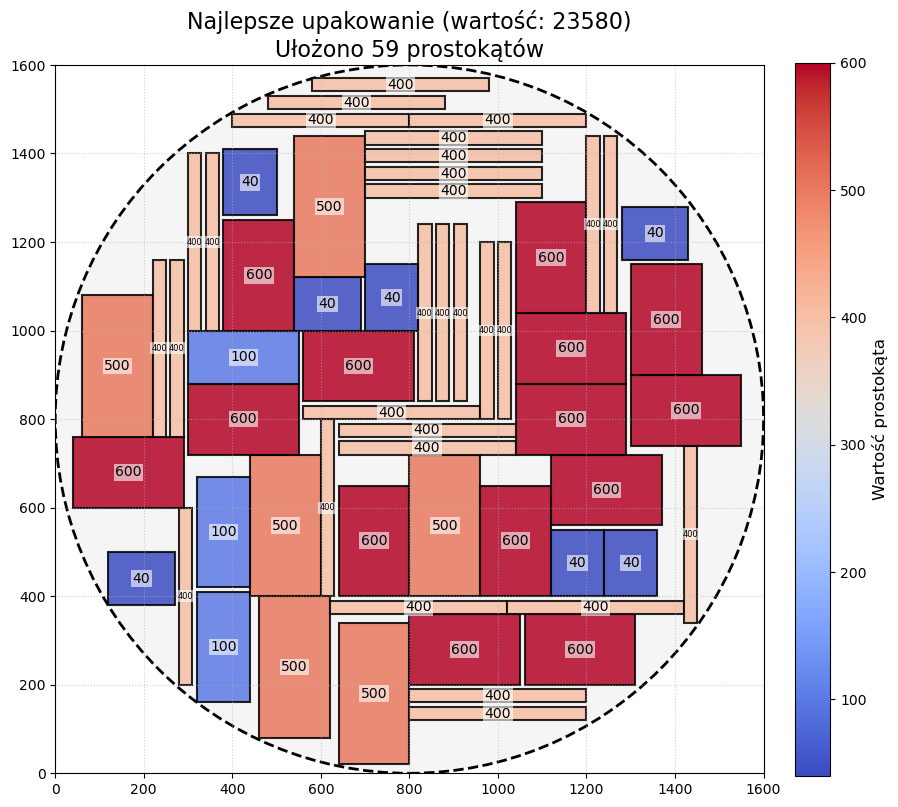

In [278]:
draw_packing(best_individual_800, radius=R, rectangles_pool=rectangles_pool)

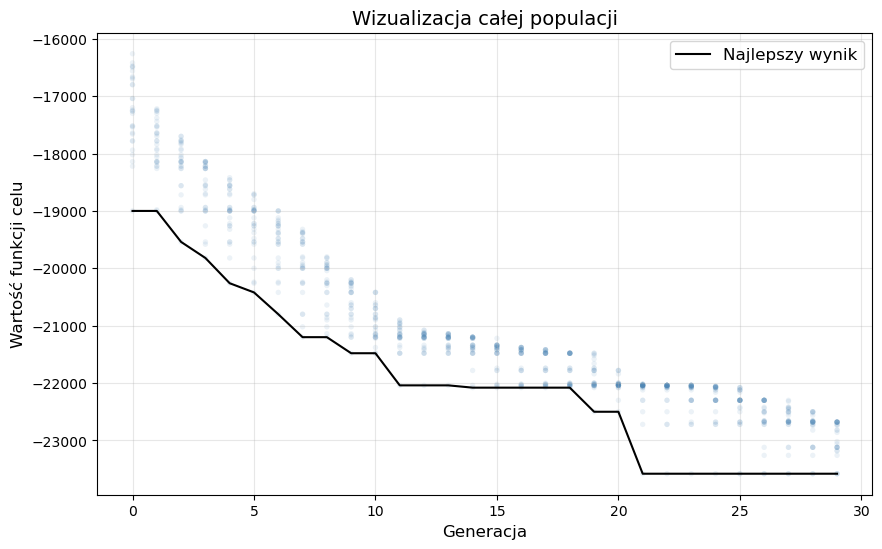

In [275]:
plot(hist_all_800, hist_best_800)

# R=850

In [279]:
r = pd.read_csv("cutting/r850.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 850
num_types = len(rectangles_pool)

In [242]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_850 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=200,
    crossover_prob=0.9,
    mutation_prob=0.5
)

best_individual_850, neg_best_score_850, hist_best_850, hist_all_850 = ea_850.train(generations=10)

print(f"Najlepszy wynik: {-neg_best_score_850}")

Inicjalizacja: 100%|██████████| 30/30 [00:30<00:00,  1.03s/it]


Generacja 0: Najlepszy = -409090.0000, Średni = -368694.6667
Generacja 1: Najlepszy = -409090.0000, Średni = -379280.3333
Generacja 2: Najlepszy = -409090.0000, Średni = -388346.6667
Generacja 3: Najlepszy = -409090.0000, Średni = -394904.0000
Generacja 4: Najlepszy = -409090.0000, Średni = -398831.0000
Generacja 5: Najlepszy = -423440.0000, Średni = -403544.0000
Generacja 6: Najlepszy = -426800.0000, Średni = -409195.6667
Generacja 7: Najlepszy = -426800.0000, Średni = -413834.6667
Generacja 8: Najlepszy = -426800.0000, Średni = -417852.3333
Generacja 9: Najlepszy = -427190.0000, Średni = -420613.0000
Najlepszy wynik: 427190


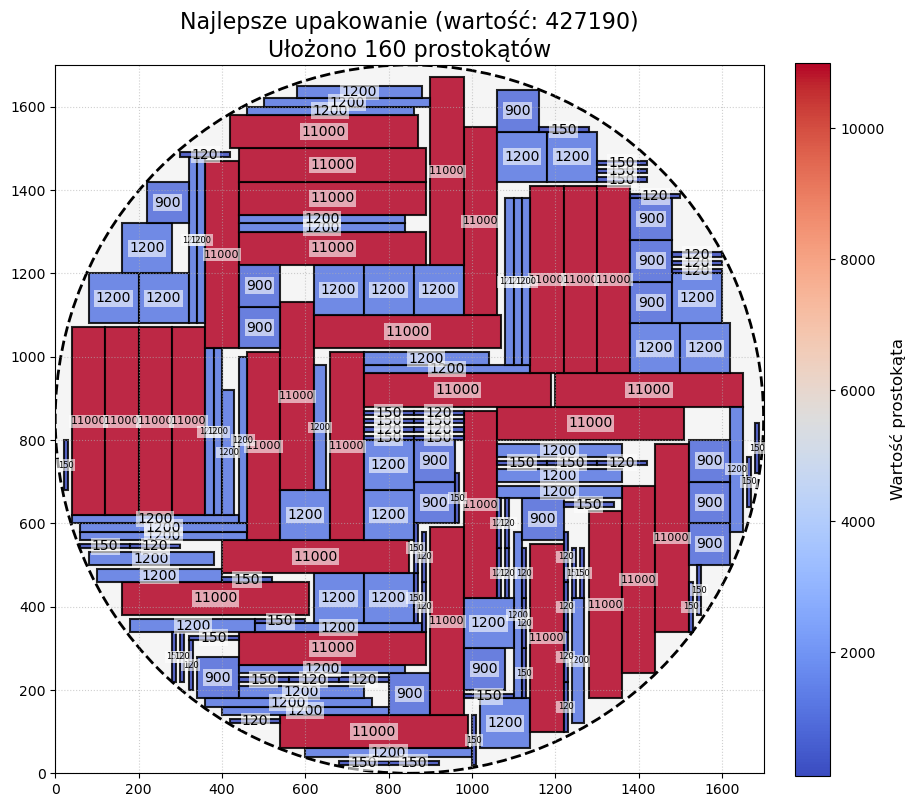

In [280]:
draw_packing(best_individual_850, radius=R, rectangles_pool=rectangles_pool)

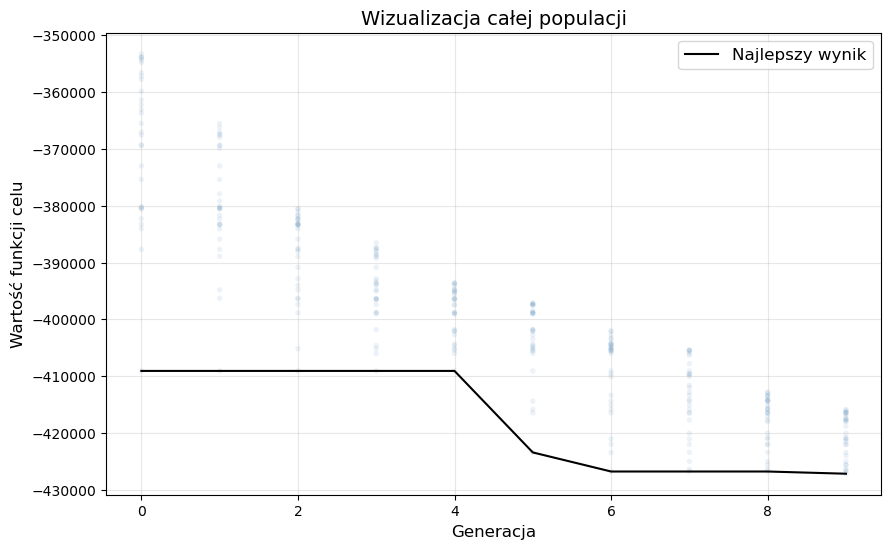

In [244]:
plot(hist_all_850, hist_best_850)

# R=1000

In [281]:
r = pd.read_csv("cutting/r1000.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1000
num_types = len(rectangles_pool)

In [246]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1000 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=120,
    crossover_prob=0.9,
    mutation_prob=0.5
)

best_individual_1000, neg_best_score_1000, hist_best_1000, hist_all_1000 = ea_1000.train(generations=10)

print(f"Najlepszy wynik: {-neg_best_score_1000}")

Inicjalizacja: 100%|██████████| 30/30 [00:26<00:00,  1.12it/s]


Generacja 0: Najlepszy = -26220.0000, Średni = -25166.6667
Generacja 1: Najlepszy = -26220.0000, Średni = -25473.3333
Generacja 2: Najlepszy = -26260.0000, Średni = -25698.0000
Generacja 3: Najlepszy = -26400.0000, Średni = -25917.3333
Generacja 4: Najlepszy = -26980.0000, Średni = -26140.0000
Generacja 5: Najlepszy = -27160.0000, Średni = -26331.3333
Generacja 6: Najlepszy = -27160.0000, Średni = -26524.0000
Generacja 7: Najlepszy = -27380.0000, Średni = -26701.3333
Generacja 8: Najlepszy = -28080.0000, Średni = -26910.0000
Generacja 9: Najlepszy = -28080.0000, Średni = -27050.0000
Najlepszy wynik: 28080


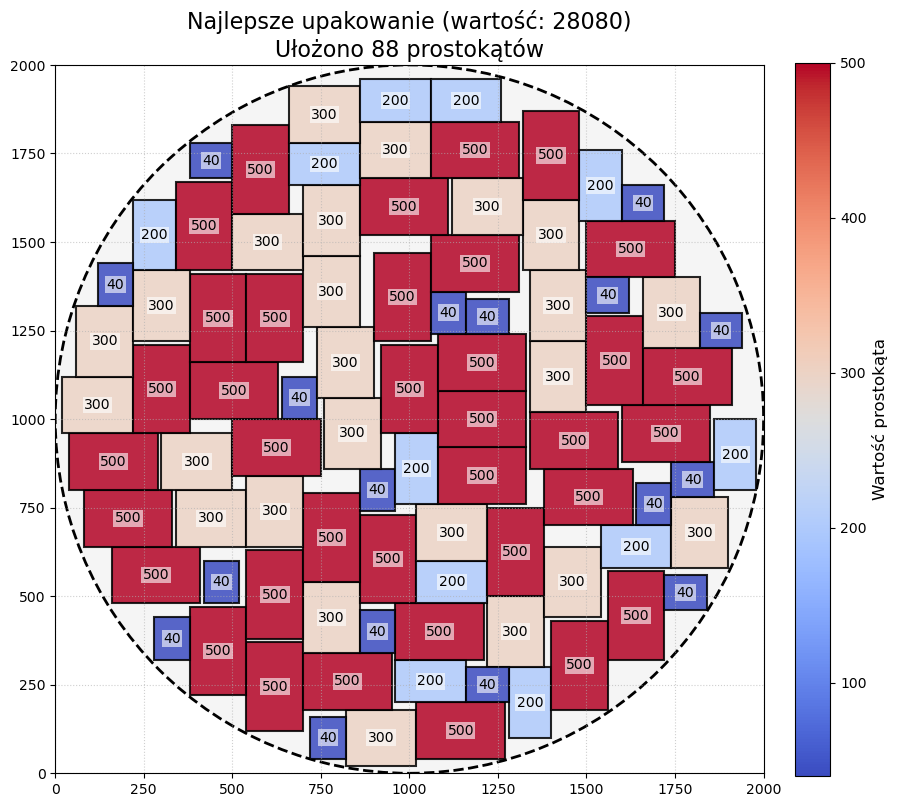

In [282]:
draw_packing(best_individual_1000, radius=R, rectangles_pool=rectangles_pool)

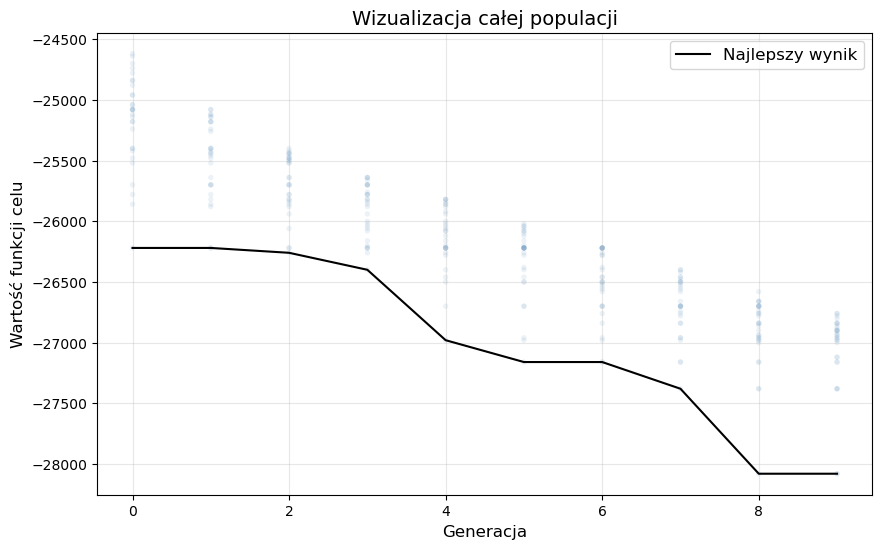

In [248]:
plot(hist_all_1000, hist_best_1000)

# R=1100

In [283]:
r = pd.read_csv("cutting/r1100.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1100
num_types = len(rectangles_pool)

In [250]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1100 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=120,
    crossover_prob=0.9,
    mutation_prob=0.5
)

best_individual_1100, neg_best_score_1100, hist_best_1100, hist_all_1100 = ea_1100.train(generations=10)

print(f"Najlepszy wynik: {-neg_best_score_1100}")

Inicjalizacja: 100%|██████████| 30/30 [00:35<00:00,  1.17s/it]


Generacja 0: Najlepszy = -26040.0000, Średni = -24161.3333
Generacja 1: Najlepszy = -27160.0000, Średni = -24871.3333
Generacja 2: Najlepszy = -27160.0000, Średni = -25563.3333
Generacja 3: Najlepszy = -27500.0000, Średni = -26060.0000
Generacja 4: Najlepszy = -27780.0000, Średni = -26598.0000
Generacja 5: Najlepszy = -29120.0000, Średni = -26940.0000
Generacja 6: Najlepszy = -29180.0000, Średni = -27304.6667
Generacja 7: Najlepszy = -29180.0000, Średni = -27814.6667
Generacja 8: Najlepszy = -29800.0000, Średni = -28323.3333
Generacja 9: Najlepszy = -29920.0000, Średni = -28812.0000
Najlepszy wynik: 29920


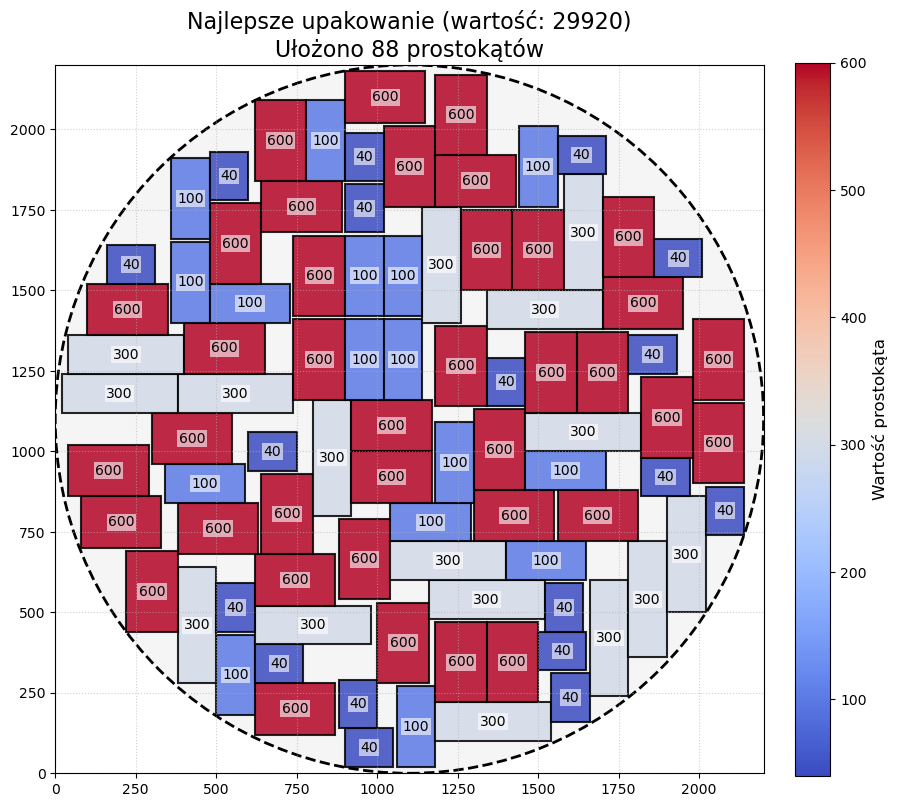

In [284]:
draw_packing(best_individual_1100, radius=R, rectangles_pool=rectangles_pool)

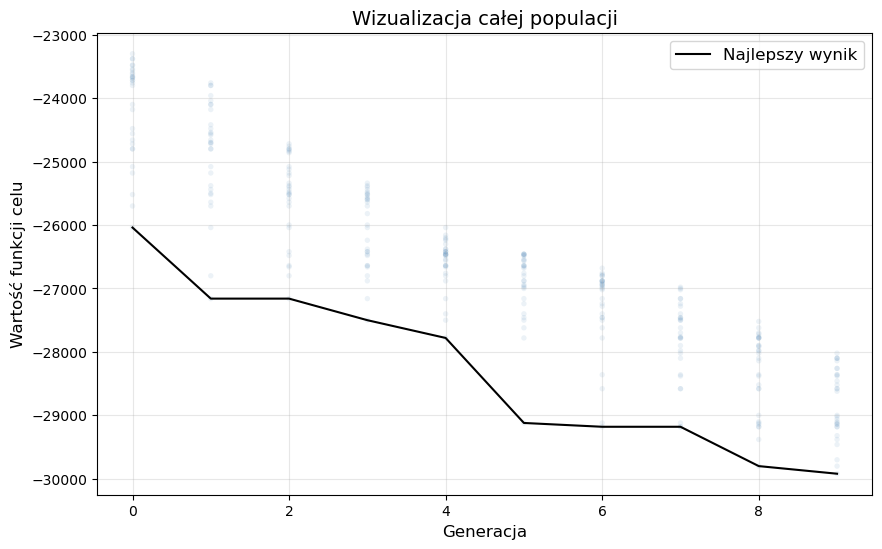

In [252]:
plot(hist_all_1100, hist_best_1100)

# R=1200

In [285]:
r = pd.read_csv("cutting/r1200.csv", header=None)
r.columns = ['width', 'height', 'value']

r_rotated = r[['height', 'width', 'value']].copy()
r_rotated.columns = ['width', 'height', 'value']

rectangles_pool = pd.concat([r, r_rotated]).reset_index(drop=True)

R = 1200
num_types = len(rectangles_pool)

In [254]:
fitness_func = lambda ind: cutting_stock_fitness(ind, radius=R, rectangles_pool=rectangles_pool)
mut_func = lambda ind: discrete_mutation(ind, num_types=num_types)

ea_1200 = EvolutionaryAlgorithm(
    objective_func=fitness_func,
    mutation_op=mut_func,
    crossover_op=single_point_crossover, 
    selection_op=rank_selection, 
    num_types=num_types,
    pop_size=30, 
    chromosome_length=160,
    crossover_prob=0.9,
    mutation_prob=0.5
)

best_individual_1200, neg_best_score_1200, hist_best_1200, hist_all_1200 = ea_1200.train(generations=10)

print(f"Najlepszy wynik: {-neg_best_score_1200}")

Inicjalizacja: 100%|██████████| 30/30 [00:50<00:00,  1.67s/it]


Generacja 0: Najlepszy = -38240.0000, Średni = -37022.6667
Generacja 1: Najlepszy = -38500.0000, Średni = -37442.6667
Generacja 2: Najlepszy = -39200.0000, Średni = -37804.6667
Generacja 3: Najlepszy = -39200.0000, Średni = -38093.3333
Generacja 4: Najlepszy = -39200.0000, Średni = -38342.0000
Generacja 5: Najlepszy = -39200.0000, Średni = -38556.0000
Generacja 6: Najlepszy = -39200.0000, Średni = -38768.6667
Generacja 7: Najlepszy = -39340.0000, Średni = -38926.6667
Generacja 8: Najlepszy = -39680.0000, Średni = -39081.3333
Generacja 9: Najlepszy = -39860.0000, Średni = -39247.3333
Najlepszy wynik: 39860


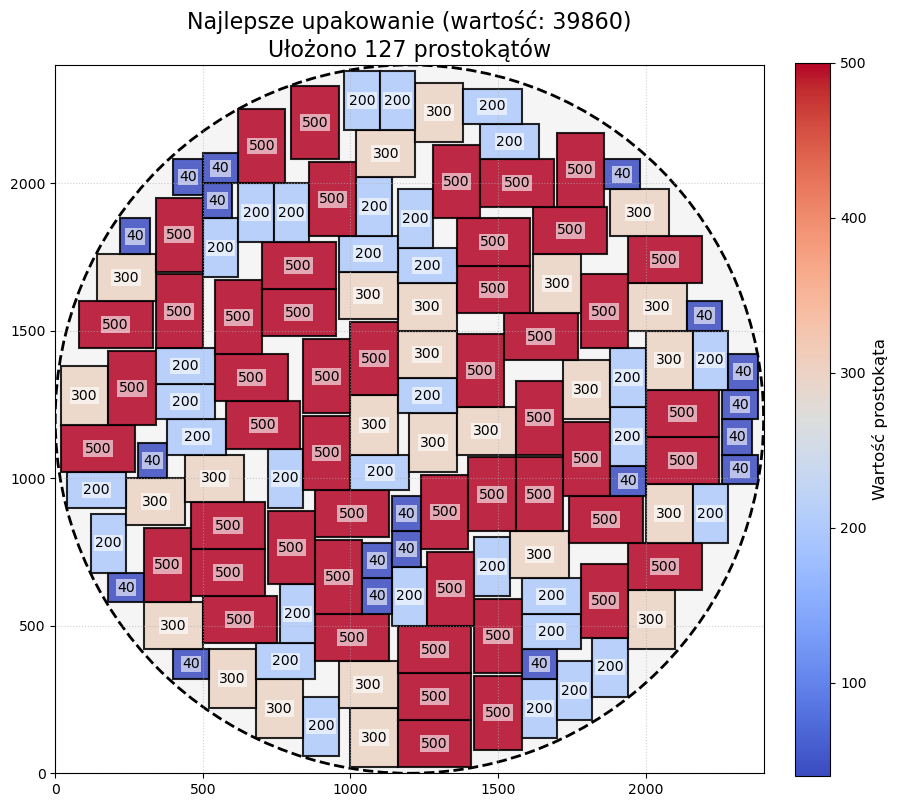

In [286]:
draw_packing(best_individual_1200, radius=R, rectangles_pool=rectangles_pool)

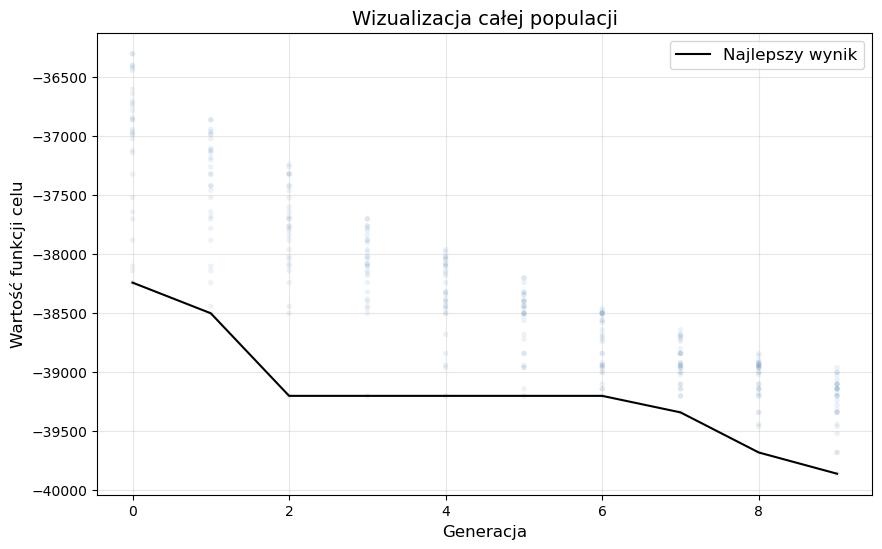

In [256]:
plot(hist_all_1200, hist_best_1200)